# PRAKTIKUM 04 — Klasifikasi Menggunakan K-Nearest Neighbors (KNN)

**Tema:** *From Data to Machine Learning*  
**Posisi:** Setelah Praktikum 01 (Python dan EDA), Praktikum 02 (Feature Space), dan Praktikum 03 (Data Preprocessing).  
**Dataset:** `Social_Network_Ads.csv` (400 observasi; label `Purchased`).  
**Estimasi:** 120–150 menit pembelajaran terarah + latihan mandiri.  
**Tingkat:** Pemula → menengah awal.

> **Cakupan modul:** membangun model klasifikasi pertama dengan KNN, memahami jarak dan pemilihan `k`, membandingkan baseline, serta menguji model secara benar. Modul ini **tidak mengulang** pembahasan detail imputasi/scaling (Praktikum 03) dan tidak membahas deployment secara mendalam (Praktikum 07–08).

## A. Capaian pembelajaran dan peta kegiatan

Setelah praktikum, mahasiswa mampu:

1. Membedakan pembelajaran *supervised classification* dari eksplorasi data.
2. Menjelaskan prinsip *nearest neighbors*, metrik jarak Euclidean, dan arti nilai `k`.
3. Menetapkan fitur `Age`, `EstimatedSalary`, dan target `Purchased` secara eksplisit.
4. Membagi data train–test secara terstratifikasi, tanpa menggunakan test untuk memilih model.
5. Membuat `Pipeline` imputasi → scaling → KNN dan menjelaskan mengapa scaling memengaruhi jarak.
6. Memakai *cross-validation* pada training untuk membandingkan `k`.
7. Menginterpretasikan baseline, accuracy, precision, recall, F1, dan confusion matrix.
8. Menguji prediksi data baru, menelusuri salah prediksi, dan mengidentifikasi keterbatasan model.

**Urutan kegiatan:** data → ruang fitur → holdout → konsep jarak → model KNN → eksperimen scaling → validasi `k` → pengujian test → interpretasi → latihan + kunci jawaban.

## B. Persiapan environment dan pemeriksaan data

**Prasyarat:** `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `joblib`, `IPython`.

File `Social_Network_Ads.csv` disertakan dalam ZIP modul, jadi **tidak ada data simulasi**. Buka notebook dari folder paket lalu lakukan **Kernel → Restart & Run All**.

Struktur paket:

```text
Praktikum_04_Klasifikasi_KNN/
├── 04_Klasifikasi_KNN_Modul_Final_dan_Jawaban.ipynb
├── praktikum/
│   └── data/
│       └── Social_Network_Ads.csv
└── README.txt
```

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
    confusion_matrix
)

SEED = 42
DATA_REL = Path('praktikum/data/Social_Network_Ads.csv')
ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / DATA_REL).is_file()),
    None
)
if ROOT is None:
    raise FileNotFoundError(
        'Social_Network_Ads.csv tidak ditemukan. Ekstrak seluruh paket ZIP dan jalankan notebook dari folder paket.'
    )
DATA_PATH = ROOT / DATA_REL
print('File ditemukan:', DATA_REL)
print('Versi pandas:', pd.__version__)

File ditemukan: praktikum/data/Social_Network_Ads.csv
Versi pandas: 2.3.1


In [2]:
df = pd.read_csv(DATA_PATH)
print('Ukuran dataset:', df.shape)
display(df.head(8))
print('Daftar kolom:', df.columns.tolist())

Ukuran dataset: (400, 5)


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0
5,15728773,Male,27,58000,0
6,15598044,Female,27,84000,0
7,15694829,Female,32,150000,1


Daftar kolom: ['User ID', 'Gender', 'Age', 'EstimatedSalary', 'Purchased']


### B1. Pahami variabel dan sasaran klasifikasi

| Kolom | Tipe | Peran di modul ini |
|---|---|---|
| `User ID` | Identitas | **Dikeluarkan**; bukan sinyal perilaku yang layak diasumsikan prediktif |
| `Gender` | Kategorikal | Ada di sumber, tetapi **tidak digunakan** agar visualisasi dua dimensi jelas |
| `Age` | Numerik | Fitur X₁ (usia) |
| `EstimatedSalary` | Numerik | Fitur X₂ (estimasi gaji) |
| `Purchased` | 0/1 | Target y: 0 = tidak membeli, 1 = membeli |

Ini **pemilihan fitur untuk demonstrasi**, bukan klaim bahwa dua fitur tersebut pasti paling baik. Gender dan identifier tidak digunakan dalam model pada modul ini. Jangan menafsirkan label dataset sebagai keputusan nyata untuk individu.

In [3]:
print('Tipe data:')
display(df.dtypes.to_frame('dtype'))
print('Missing value per kolom:')
display(df.isna().sum().to_frame('jumlah_missing'))
print('Duplikasi baris:', int(df.duplicated().sum()))
print('Frekuensi kelas Purchased:')
display(df['Purchased'].value_counts().sort_index().to_frame('jumlah'))
assert set(df['Purchased'].dropna().unique()) == {0, 1}, 'Target harus biner 0/1'
assert df.shape[0] == 400, 'Dataset tidak sama dengan versi workshop (400 baris)'

Tipe data:


,dtype
User ID,int64
Gender,object
Age,int64
EstimatedSalary,int64
Purchased,int64


Missing value per kolom:


,jumlah_missing
User ID,0
Gender,0
Age,0
EstimatedSalary,0
Purchased,0


Duplikasi baris: 0
Frekuensi kelas Purchased:


,jumlah
Purchased,
0,257
1,143


### B2. Visualisasi eksploratif: apakah dua kelas tampak terpisah?

Sumbu x adalah usia dan sumbu y adalah estimasi gaji. **Warna menunjukkan label aktual**, bukan hasil prediksi model. Titik dengan warna berbeda bisa saling berdekatan; karena itu prediksi KNN tidak selalu benar.

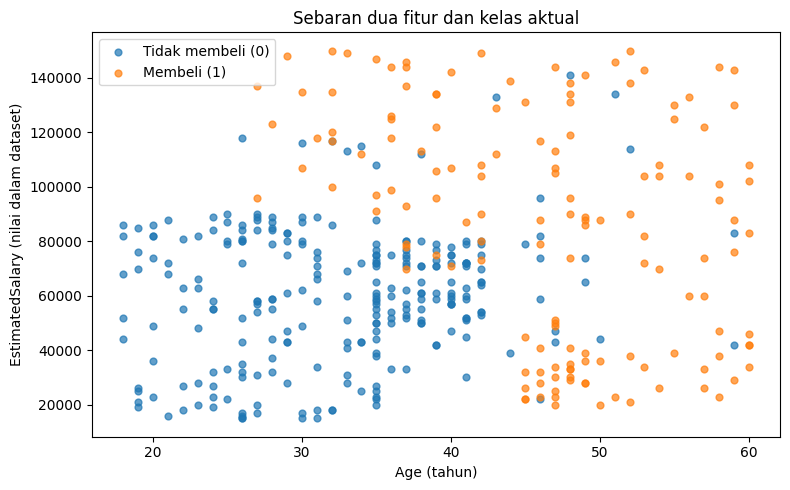

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
for label, nama in [(0, 'Tidak membeli (0)'), (1, 'Membeli (1)')]:
    part = df.loc[df['Purchased'] == label]
    ax.scatter(part['Age'], part['EstimatedSalary'], label=nama, alpha=0.7, s=24)
ax.set(xlabel='Age (tahun)', ylabel='EstimatedSalary (nilai dalam dataset)',
       title='Sebaran dua fitur dan kelas aktual')
ax.legend()
fig.tight_layout()
plt.show()

## C. Input Space → Feature Space → Target

Pada Praktikum 02, kita sudah mempelajari bahwa **satu record** dapat direpresentasikan oleh suatu vektor fitur. Sekarang kita gunakan vektor tersebut sebagai masukan KNN:

\[
\mathbf{x}_i=\begin{bmatrix}\text{Age}_i & \text{EstimatedSalary}_i\end{bmatrix},
\qquad y_i\in\{0,1\}.
\]

Matriks fitur `X` memiliki bentuk **(400, 2)**; target `y` mempunyai **400 label**. Karena nilainya numerik, fitur dapat dipakai untuk perhitungan jarak setelah penanganan skala.

In [5]:
feature_cols = ['Age', 'EstimatedSalary']
target_col = 'Purchased'
X = df.loc[:, feature_cols].copy()
y = df[target_col].copy()
print('X.shape:', X.shape)
print('y.shape:', y.shape)
print('Satu vektor fitur (record 0):', X.iloc[0].to_numpy())
print('Label aktual:', int(y.iloc[0]))
display(X.head())

X.shape: (400, 2)
y.shape: (400,)
Satu vektor fitur (record 0): [   19 19000]
Label aktual: 0


,Age,EstimatedSalary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000


## D. Train–test split: data untuk belajar vs data untuk evaluasi akhir

Gunakan **75% train** dan **25% test** secara stratifikasi (`stratify=y`) untuk mempertahankan proporsi label. `random_state=42` memungkinkan pembagian direproduksi.

> **Aturan penting:** Kita memilih `k` dan mempelajari preprocessing hanya dari **training**. Test disimpan sebagai evaluasi akhir (holdout), tidak dilibatkan dalam pemilihan `k` ataupun proses `fit`.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)
assert set(X_train.index).isdisjoint(set(X_test.index))
print('Train:', X_train.shape, '| Test:', X_test.shape)
ringkasan_split = pd.DataFrame({
    'train_n': y_train.value_counts().sort_index(),
    'test_n': y_test.value_counts().sort_index(),
    'train_proporsi': y_train.value_counts(normalize=True).sort_index(),
    'test_proporsi': y_test.value_counts(normalize=True).sort_index(),
}).rename_axis('Purchased')
display(ringkasan_split.round(3))

Train: (300, 2) | Test: (100, 2)


,train_n,test_n,train_proporsi,test_proporsi
Purchased,,,,
0,193,64,0.643,0.64
1,107,36,0.357,0.36


## E. Dasar KNN: menghitung jarak dan voting mayoritas

KNN disebut metode *instance-based learning*: label diperkirakan berdasarkan label tetangga terdekat dari data training. Untuk fitur numerik dan metrik Euclidean:

\[
d(\mathbf{x},\mathbf{z})=\sqrt{\sum_{j=1}^{p}(x_j-z_j)^2}.
\]

**Alur prediksi:** (1) terima record baru, (2) hitung jaraknya ke record training, (3) pilih `k` tetangga paling dekat, (4) tentukan kelas dengan suara terbanyak.

`k=1` sangat sensitif terhadap tetangga tunggal; `k` terlalu besar cenderung lebih halus dan bisa melewatkan pola setempat. Nilai `k` dipilih berdasarkan validasi, bukan ditebak dari data test. Secara default scikit-learn memakai bobot tetangga seragam (`weights='uniform'`).

### E1. Perhitungan jarak Euclidean manual (dua record ilustratif)

Contoh kecil berikut **bukan** bagian dari dataset. Tujuannya melihat bagaimana jarak bekerja tanpa perlu menggunakan library KNN.

In [7]:
p = np.array([20., 30000.])
q = np.array([30., 80000.])
jarak_manual = np.sqrt(((p - q) ** 2).sum())
jarak_numpy = np.linalg.norm(p - q)
print('P:', p, '| Q:', q)
print('Jarak Euclidean:', round(jarak_manual, 2))
assert np.isclose(jarak_manual, jarak_numpy)
print('Perbedaan pada EstimatedSalary mendominasi jarak mentah.')

P: [2.e+01 3.e+04] | Q: [3.e+01 8.e+04]
Jarak Euclidean: 50000.0
Perbedaan pada EstimatedSalary mendominasi jarak mentah.


### E2. Mengapa scaling penting untuk KNN?

Selisih 10 tahun usia tampak kecil dibanding selisih gaji sebesar puluhan ribu dalam satuan asli. Akibatnya, tanpa scaling, kedekatan dapat didominasi oleh fitur gaji.

Praktikum 03 telah membahas cara kerja `StandardScaler`; dalam modul ini scaler akan **dimasukkan ke Pipeline**, sehingga statistiknya dipelajari dari training saja. Kita tidak melakukan `fit_transform(X)` sebelum train–test split.

In [8]:
# Untuk demonstrasi: scaler dipelajari hanya dari TRAIN
scaler_demo = StandardScaler().fit(X_train)
p_scaled, q_scaled = scaler_demo.transform(pd.DataFrame([p, q], columns=feature_cols))
print('P setelah StandardScaler:', np.round(p_scaled, 3))
print('Q setelah StandardScaler:', np.round(q_scaled, 3))
print('Jarak setelah scaling:', round(float(np.linalg.norm(p_scaled - q_scaled)), 3))
print('Rata-rata fitur TRAIN:', np.round(scaler_demo.mean_, 2))

P setelah StandardScaler: [-1.616 -1.163]
Q setelah StandardScaler: [-0.673  0.259]
Jarak setelah scaling: 1.706
Rata-rata fitur TRAIN: [3.714000e+01 7.090333e+04]


## F. Model awal: Pipeline KNN dengan k=5

Modul asli memilih `k=5` dan menggabungkan tiga langkah:

1. `SimpleImputer(strategy='median')`: menangani nilai numerik kosong (dataset ini kebetulan tidak memiliki nilai kosong).
2. `StandardScaler()`: menyetarakan skala fitur memakai rata-rata/simpangan baku training.
3. `KNeighborsClassifier(n_neighbors=5)`: membangun mekanisme tetangga.

Kombinasi dalam `Pipeline` menghindari ketidaksengajaan melakukan *fit* preprocessing pada test.

In [9]:
def make_knn(k=5, with_scaling=True, weights='uniform'):
    langkah = [('imputer', SimpleImputer(strategy='median'))]
    if with_scaling:
        langkah.append(('scaler', StandardScaler()))
    langkah.append(('knn', KNeighborsClassifier(n_neighbors=k, weights=weights)))
    return Pipeline(langkah)

model_knn_5 = make_knn(k=5)
model_knn_5.fit(X_train, y_train)
print(model_knn_5)
print('Jumlah record untuk fit:', model_knn_5.named_steps['knn'].n_samples_fit_)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])
Jumlah record untuk fit: 300


### F1. Bagaimana model menetapkan label satu data baru?

Jalankan `kneighbors()` pada representasi **setelah preprocessing**. Indeks tetangga berasal dari urutan training yang dipakai saat `fit`, bukan indeks baris CSV asli.

In [10]:
# Pilih satu record dari holdout; jangan gunakan labelnya untuk memilih k
query = X_test.iloc[[0]]
query_imp = model_knn_5.named_steps['imputer'].transform(query)
query_scaled = model_knn_5.named_steps['scaler'].transform(query_imp)
jarak, posisi = model_knn_5.named_steps['knn'].kneighbors(query_scaled, n_neighbors=5)

neighbors = X_train.iloc[posisi[0]].copy()
neighbors['kelas_aktual_tetangga'] = y_train.iloc[posisi[0]].to_numpy()
neighbors['jarak_standar'] = jarak[0]
print('Record yang ingin diprediksi:')
display(query)
print('Lima tetangga terdekat:')
display(neighbors.round(3))
print('Voting kelas 5 tetangga:', neighbors['kelas_aktual_tetangga'].value_counts().to_dict())
print('Prediksi:', int(model_knn_5.predict(query)[0]))

Record yang ingin diprediksi:


,Age,EstimatedSalary
315,39,75000


Lima tetangga terdekat:


,Age,EstimatedSalary,kelas_aktual_tetangga,jarak_standar
348,39,77000,0,0.057
266,40,75000,0,0.094
387,39,71000,0,0.114
314,39,79000,0,0.114
110,39,71000,0,0.114


Voting kelas 5 tetangga: {0: 5}
Prediksi: 0


### F2. Visualisasi tetangga di ruang fitur terstandar

Bentuk sebaran setelah scaling dapat berubah karena sumbu tidak lagi memakai satuan tahun dan gaji. Lingkaran kosong menandai tetangga terdekat; simbol bintang menandai record query.

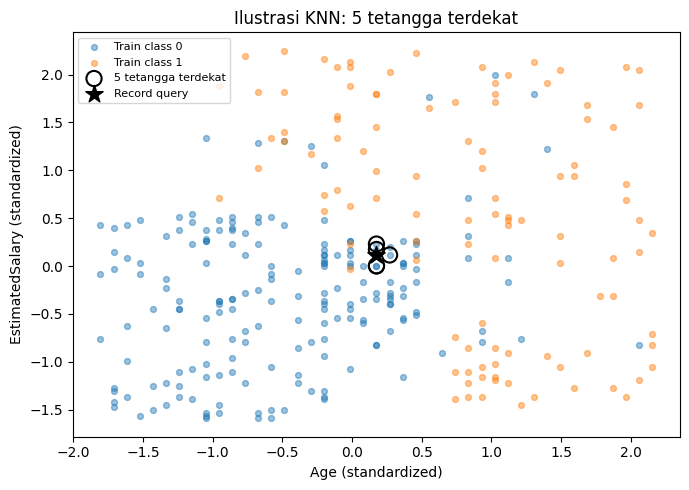

In [11]:
train_imp = model_knn_5.named_steps['imputer'].transform(X_train)
train_scaled = model_knn_5.named_steps['scaler'].transform(train_imp)
fig, ax = plt.subplots(figsize=(7, 5))
for kelas in [0, 1]:
    sel = y_train.to_numpy() == kelas
    ax.scatter(train_scaled[sel, 0], train_scaled[sel, 1],
               s=18, alpha=0.45, label=f'Train class {kelas}')
ax.scatter(train_scaled[posisi[0], 0], train_scaled[posisi[0], 1],
           s=120, facecolors='none', edgecolors='black', linewidths=1.5,
           label='5 tetangga terdekat')
ax.scatter(query_scaled[0, 0], query_scaled[0, 1],
           s=170, marker='*', color='black', label='Record query')
ax.set(xlabel='Age (standardized)', ylabel='EstimatedSalary (standardized)',
       title='Ilustrasi KNN: 5 tetangga terdekat')
ax.legend(loc='best', fontsize=8)
fig.tight_layout()
plt.show()

## G. Eksperimen terkontrol: tanpa scaling vs dengan scaling

Agar **test tidak dipakai untuk memilih model**, kedua pendekatan dibandingkan menggunakan *5-fold stratified cross-validation* pada data training saja. Setiap fold mempelajari kembali imputasi dan scaling dari subset train pada fold tersebut.

**Hipotesis:** KNN dengan scaling akan bekerja lebih baik pada data dengan perbedaan satuan sebesar ini, meskipun hasilnya harus diperiksa, bukan diasumsikan selalu benar.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_compare = []
for label, use_scale in [('Tanpa scaling', False), ('Dengan StandardScaler', True)]:
    scores = cross_val_score(
        make_knn(k=5, with_scaling=use_scale),
        X_train, y_train, cv=cv, scoring='accuracy'
    )
    cv_compare.append({
        'Metode': label, 'CV mean accuracy': scores.mean(),
        'CV std': scores.std(), 'Per fold': np.round(scores, 3).tolist()
    })
scale_comparison = pd.DataFrame(cv_compare)
display(scale_comparison)

,Metode,CV mean accuracy,CV std,Per fold
0,Tanpa scaling,0.800000,0.02357,"[0.8, 0.767, 0.833, 0.783, 0.817]"
1,Dengan StandardScaler,0.893333,0.03266,"[0.867, 0.933, 0.867, 0.867, 0.933]"


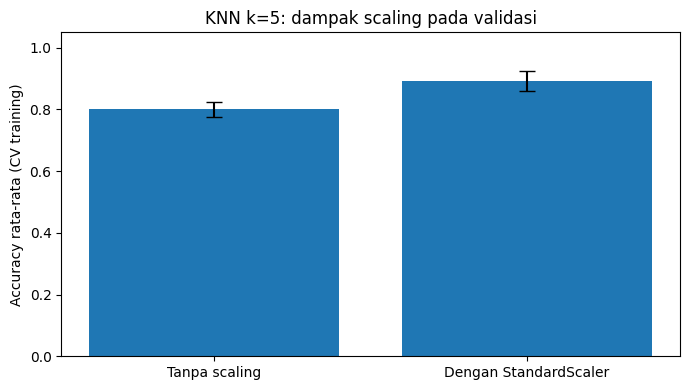

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(scale_comparison['Metode'], scale_comparison['CV mean accuracy'],
       yerr=scale_comparison['CV std'], capsize=6)
ax.set(ylabel='Accuracy rata-rata (CV training)',
       title='KNN k=5: dampak scaling pada validasi')
ax.set_ylim(0, 1.05)
fig.tight_layout()
plt.show()

**Interpretasi:** nilai dalam tabel adalah *skor validasi training*, bukan performa pada test akhir. Perbedaan rata-rata memberi indikasi apakah scaling berguna pada data ini; simpangan baku menunjukkan variasi antar-fold. Evaluasi final tetap dilakukan hanya setelah seluruh keputusan eksperimen training selesai.

## H. Memilih nilai k menggunakan cross-validation

KNN memiliki hiperparameter utama `n_neighbors=k`. Kita uji sekumpulan nilai ganjil yang layak untuk ukuran training. Penggunaan angka ganjil membantu mengurangi kemungkinan seri voting pada klasifikasi dua kelas dengan bobot seragam.

- **Jangan:** memilih `k` berdasarkan accuracy yang tertinggi pada test.
- **Lakukan:** hitung performa pada fold validasi training, pilih `k` terbaik berdasarkan aturan konsisten, fit ulang pada semua training, lalu evaluasi sekali pada test.

In [14]:
k_candidates = [1, 3, 5, 7, 9, 11, 15, 21, 31]
rows = []
for k in k_candidates:
    scores = cross_val_score(
        make_knn(k=k), X_train, y_train, cv=cv, scoring='accuracy'
    )
    rows.append({'k': k, 'cv_mean_accuracy': float(scores.mean()),
                 'cv_std_accuracy': float(scores.std())})
cv_table = pd.DataFrame(rows)
# Aturan tie-break: pilih k yang lebih kecil jika rata-ratanya sama
cv_sorted = cv_table.sort_values(['cv_mean_accuracy', 'k'], ascending=[False, True])
best_k = int(cv_sorted.iloc[0]['k'])
print('Pilihan k berdasarkan CV training:', best_k)
display(cv_table.round(4))

Pilihan k berdasarkan CV training: 7


,k,cv_mean_accuracy,cv_std_accuracy
0,1,0.8600,0.0429
1,3,0.9000,0.0365
2,5,0.8933,0.0327
3,7,0.9067,0.0467
4,9,0.9033,0.0499
5,11,0.9033,0.0591
6,15,0.9033,0.0488
7,21,0.9000,0.0471
8,31,0.8933,0.0403


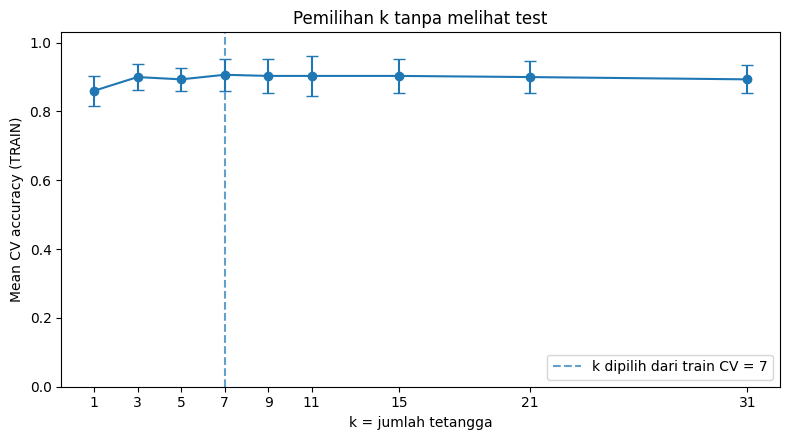

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(cv_table['k'], cv_table['cv_mean_accuracy'],
            yerr=cv_table['cv_std_accuracy'], marker='o', capsize=4)
ax.axvline(best_k, linestyle='--', alpha=0.7,
           label=f'k dipilih dari train CV = {best_k}')
ax.set(xlabel='k = jumlah tetangga', ylabel='Mean CV accuracy (TRAIN)',
       title='Pemilihan k tanpa melihat test')
ax.set_xticks(k_candidates)
ax.set_ylim(0, 1.03)
ax.legend()
fig.tight_layout()
plt.show()

### H1. Apa arti pola kurva k?

Skor yang berubah tajam pada `k` kecil dapat menunjukkan sensitivitas pada observasi lokal. Pada `k` besar, model lebih menghaluskan keputusan. **Namun, kurva tunggal dari satu pembagian dan satu konfigurasi CV belum membuktikan adanya overfitting atau underfitting secara menyeluruh.** Ini adalah eksperimen awal untuk memahami bias–variance tradeoff.

## I. Model final dan baseline: evaluasi pada holdout test

Sekarang kita baru menggunakan `X_test, y_test`. Bandingkan:

- `DummyClassifier(strategy='most_frequent')`: selalu menebak kelas paling sering di training.
- KNN dengan `best_k` hasil cross-validation.

Metrik **accuracy** perlu dilengkapi dengan **precision**, **recall**, **F1**, serta **confusion matrix** karena proporsi kelas tidak sama. Pada laporan berikut, metrik precision/recall/F1 memakai kelas positif `Purchased=1`.

In [16]:
final_model = make_knn(k=best_k)
final_model.fit(X_train, y_train)
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)

pred_test = final_model.predict(X_test)
pred_baseline = baseline.predict(X_test)

def metrik_binary(y_true, y_pred):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'precision_1': precision_score(y_true, y_pred, zero_division=0),
        'recall_1': recall_score(y_true, y_pred, zero_division=0),
        'f1_1': f1_score(y_true, y_pred, zero_division=0)
    }

hasil_test = pd.DataFrame([
    {'Model': 'Baseline mayoritas', **metrik_binary(y_test, pred_baseline)},
    {'Model': f'KNN hasil CV (k={best_k})', **metrik_binary(y_test, pred_test)}
]).set_index('Model')
print('EVALUASI AKHIR — HOLDOUT TEST (bukan CV)')
display(hasil_test.round(3))

EVALUASI AKHIR — HOLDOUT TEST (bukan CV)


,accuracy,balanced_accuracy,precision_1,recall_1,f1_1
Model,,,,,
Baseline mayoritas,0.64,0.500,0.000,0.000,0.000
KNN hasil CV (k=7),0.92,0.913,0.889,0.889,0.889


### I1. Cara membaca metrik

- **Accuracy:** proporsi prediksi tepat dari semua record.
- **Precision kelas 1:** dari semua prediksi `beli`, berapa yang benar-benar `beli`?
- **Recall kelas 1:** dari seluruh kasus yang benar-benar `beli`, berapa yang ditemukan model?
- **F1 kelas 1:** rata-rata harmonik precision dan recall.
- **Balanced accuracy:** rata-rata recall masing-masing kelas; berguna saat distribusi kelas tidak seimbang.

**Contoh interpretasi:** Recall kelas 1 = 0,80 berarti sekitar 80% kasus positif pada test berhasil dideteksi; angka ini bukan ukuran kepastian prediksi individual.

In [17]:
print('Classification Report (KNN final, test):')
print(classification_report(
    y_test, pred_test, labels=[0, 1],
    target_names=['Tidak membeli (0)', 'Membeli (1)'],
    digits=3, zero_division=0
))

Classification Report (KNN final, test):
                   precision    recall  f1-score   support

Tidak membeli (0)      0.938     0.938     0.938        64
      Membeli (1)      0.889     0.889     0.889        36

         accuracy                          0.920       100
        macro avg      0.913     0.913     0.913       100
     weighted avg      0.920     0.920     0.920       100



### I2. Confusion matrix dan kesalahan model

Konvensi untuk `labels=[0,1]`:

| | Prediksi 0 | Prediksi 1 |
|---|---:|---:|
| **Aktual 0** | TN | FP |
| **Aktual 1** | FN | TP |

`FP` = model memprediksi membeli padahal tidak; `FN` = model memprediksi tidak membeli padahal membeli.

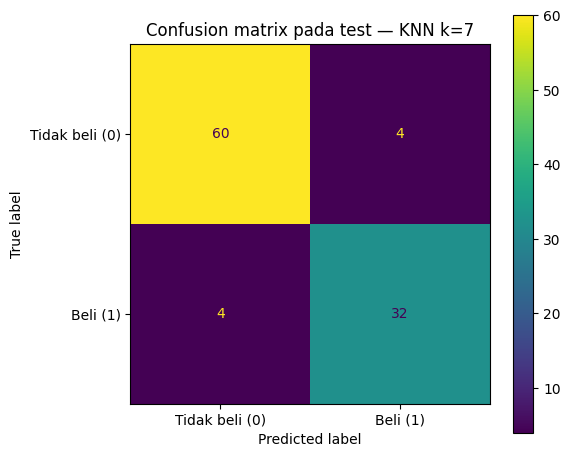

TN=60, FP=4, FN=4, TP=32


In [18]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_test, labels=[0, 1],
    display_labels=['Tidak beli (0)', 'Beli (1)'],
    values_format='d', ax=ax
)
ax.set_title(f'Confusion matrix pada test — KNN k={best_k}')
fig.tight_layout()
plt.show()
tn, fp, fn, tp = confusion_matrix(y_test, pred_test, labels=[0,1]).ravel()
print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}')

### I3. Menelusuri record yang salah diprediksi

Kesalahan dikaji pada test **setelah evaluasi final**, untuk memahami keterbatasan. Jangan memakai daftar kesalahan ini untuk memilih ulang `k` lalu melaporkan akurasi pada test yang sama sebagai hasil final baru.

In [19]:
prob_test = final_model.predict_proba(X_test)[:, list(final_model.named_steps['knn'].classes_).index(1)]
test_detail = X_test.copy()
test_detail['actual'] = y_test.to_numpy()
test_detail['predicted'] = pred_test
test_detail['score_class_1'] = prob_test
wrong = test_detail.loc[test_detail['actual'] != test_detail['predicted']]
print('Jumlah salah prediksi:', len(wrong), 'dari', len(test_detail))
display(wrong.head(12).round(3))

Jumlah salah prediksi: 8 dari 100


,Age,EstimatedSalary,actual,predicted,score_class_1
315,39,75000,1,0,0.000
358,40,71000,1,0,0.000
73,33,113000,0,1,0.571
234,38,112000,0,1,0.714
289,37,78000,1,0,0.143
64,59,83000,0,1,1.000
378,41,87000,1,0,0.286
209,46,22000,0,1,1.000


**Peringatan interpretasi:** skor dari `predict_proba` KNN merupakan proporsi suara tetangga pada pengaturan bobot seragam. Jangan otomatis menafsirkannya sebagai probabilitas risiko yang sudah terkalibrasi.

## J. Memahami *decision boundary* KNN

Kita bentuk grid usia–gaji lalu meminta model memprediksi setiap titik. Plot ini menunjukkan wilayah prediksi kelas 0 atau 1. KNN dapat membentuk batas yang tidak linier bahkan ketika hanya memakai dua fitur.

Grid hanya untuk visualisasi; **bukan** pengamatan baru dalam data training.

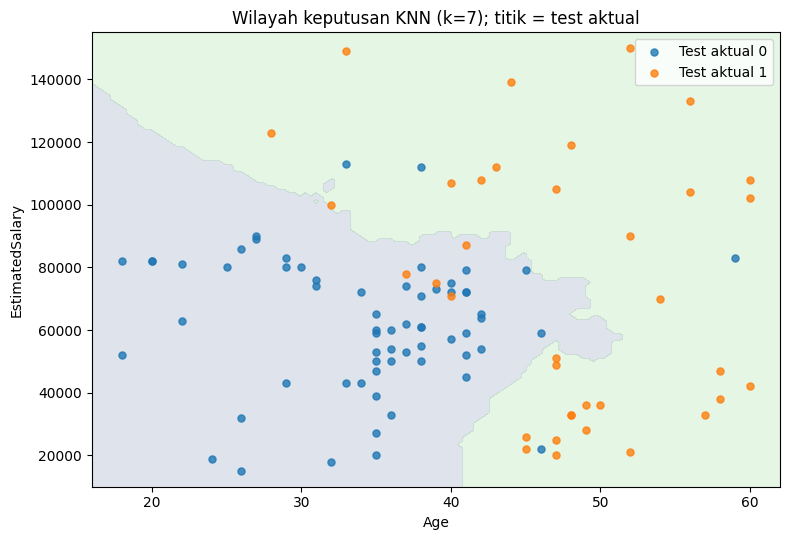

In [20]:
age_grid = np.linspace(X['Age'].min() - 2, X['Age'].max() + 2, 130)
salary_grid = np.linspace(X['EstimatedSalary'].min() - 5000,
                          X['EstimatedSalary'].max() + 5000, 130)
xx, yy = np.meshgrid(age_grid, salary_grid)
grid_df = pd.DataFrame({'Age': xx.ravel(), 'EstimatedSalary': yy.ravel()})
grid_pred = final_model.predict(grid_df).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.contourf(xx, yy, grid_pred, levels=[-0.5,0.5,1.5], alpha=0.16)
for label in [0, 1]:
    subset = X_test.loc[y_test == label]
    ax.scatter(subset['Age'], subset['EstimatedSalary'], s=26,
               label=f'Test aktual {label}', alpha=0.8)
ax.set(xlabel='Age', ylabel='EstimatedSalary',
       title=f'Wilayah keputusan KNN (k={best_k}); titik = test aktual')
ax.legend()
fig.tight_layout()
plt.show()

**Batas visualisasi:** Wilayah berwarna berasal dari prediksi pada grid, bukan batas yang diketahui benar dalam populasi. Plot menggunakan data test hanya sebagai titik pembanding setelah keputusan model dikunci.

## K. Prediksi pada record baru yang belum memiliki label

Tahap *inference* membutuhkan schema input yang sama: **`Age` dan `EstimatedSalary`**. Pipeline menjalankan imputasi dan scaling otomatis menggunakan parameter dari training.

In [21]:
new_samples = pd.DataFrame({
    'Age': [24, 50, 35],
    'EstimatedSalary': [25000, 100000, 60000]
})
new_predictions = final_model.predict(new_samples)
new_scores = final_model.predict_proba(new_samples)
classes_ = final_model.named_steps['knn'].classes_
score_idx_1 = list(classes_).index(1)
new_results = new_samples.copy()
new_results['predicted_Purchased'] = new_predictions
new_results['neighbor_vote_share_class_1'] = new_scores[:, score_idx_1]
print('Prediksi untuk record baru (contoh ilustratif):')
display(new_results.round(3))

Prediksi untuk record baru (contoh ilustratif):


,Age,EstimatedSalary,predicted_Purchased,neighbor_vote_share_class_1
0,24,25000,0,0.0
1,50,100000,1,1.0
2,35,60000,0,0.0


### K1. Apa yang terjadi bila ada input tidak valid?

Pipeline menangani `NaN` numerik melalui imputasi median, tetapi **tidak menggantikan validasi bisnis**: misalnya usia negatif atau nilai gaji berbentuk teks harus diperiksa sebelum diprediksi. Kita buat fungsi validasi sederhana.

In [22]:
def validate_new_records(records):
    if not isinstance(records, pd.DataFrame):
        raise TypeError('Input harus berupa pandas DataFrame.')
    missing_cols = [c for c in feature_cols if c not in records.columns]
    if missing_cols:
        raise ValueError(f'Kolom wajib belum ada: {missing_cols}')
    if records.empty:
        raise ValueError('Minimal diperlukan satu record.')
    valid = records.loc[:, feature_cols].copy()
    for col in feature_cols:
        valid[col] = pd.to_numeric(valid[col], errors='raise')
    if valid['Age'].dropna().lt(0).any():
        raise ValueError('Age tidak boleh negatif.')
    if valid['EstimatedSalary'].dropna().lt(0).any():
        raise ValueError('EstimatedSalary tidak boleh negatif.')
    return valid

checked = validate_new_records(new_samples)
assert checked.shape == (3, 2)
print('Validasi input berhasil; prediksi:', final_model.predict(checked).tolist())

Validasi input berhasil; prediksi: [0, 1, 0]


## L. Menyimpan artefak latihan (pengantar Praktikum 07)

Pada modul asli, model disimpan sebagai `joblib` dan hasil test diekspor ke CSV. Kita pertahankan langkah ini **sebagai pengenalan**, tanpa mendalami interoperabilitas, keamanan serialisasi, dan manajemen versi yang akan dibahas pada Praktikum 07.

> Berkas `joblib`/`pickle` hanya boleh dimuat dari sumber tepercaya karena proses deserialisasi dapat menjalankan kode arbitrer.

In [23]:
import joblib
OUTPUT_DIR = ROOT / 'praktikum' / 'hasil' / 'modul04'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model_file = OUTPUT_DIR / 'knn_pipeline_final.joblib'
pred_file = OUTPUT_DIR / 'knn_prediksi_test.csv'
report_file = OUTPUT_DIR / 'knn_evaluasi.txt'

joblib.dump(final_model, model_file)
export_pred = test_detail.reset_index(names='index_baris_asli')
export_pred.to_csv(pred_file, index=False)
report_file.write_text(
    f'KNN terpilih berdasarkan CV training: k={best_k}\n'
    + classification_report(y_test, pred_test, digits=4, zero_division=0),
    encoding='utf-8'
)
print('Model:', model_file.relative_to(ROOT))
print('Prediksi test:', pred_file.relative_to(ROOT))
print('Laporan:', report_file.relative_to(ROOT))

Model: praktikum/hasil/modul04/knn_pipeline_final.joblib
Prediksi test: praktikum/hasil/modul04/knn_prediksi_test.csv
Laporan: praktikum/hasil/modul04/knn_evaluasi.txt


### L1. Pemeriksaan konsistensi model tersimpan

Pemeriksaan sederhana ini menggunakan model yang baru saja dibuat pada komputer yang sama, **bukan** pembuktian kompatibilitas lintas versi library atau lintas lingkungan.

In [24]:
loaded_model = joblib.load(model_file)  # hanya dari berkas yang baru dibuat dan tepercaya
assert np.array_equal(loaded_model.predict(X_test), pred_test)
print('OK: hasil prediksi model yang dimuat kembali identik pada data test.')

OK: hasil prediksi model yang dimuat kembali identik pada data test.


## M. Rangkuman hasil praktikum

**Checklist interpretasi (lengkapi dari output yang benar-benar dihasilkan):**

- Apakah bentuk `X` = `(400, 2)` dan partisi train/test saling terpisah?
- Berapa distribusi kelas 0 dan kelas 1 di training dan test?
- Apa perbedaan CV accuracy model tanpa scaling vs dengan scaling?
- Berapa `best_k` yang dipilih menggunakan CV training?
- Bagaimana accuracy KNN dibandingkan baseline pada test?
- Berapa FP dan FN pada confusion matrix?
- Berapa jumlah prediksi yang salah dari 100 record test?
- Apakah model tersimpan menghasilkan prediksi yang sama setelah dimuat ulang?

**Pembatasan:** satu dataset kecil, satu seed pembagian data, satu teknik seleksi `k`, dan hanya dua fitur. Hasil pada holdout bukan jaminan generalisasi ke populasi atau dataset lain.

In [25]:
ringkasan = pd.DataFrame({
    'Aspek': ['Jumlah data', 'Data train', 'Data test', 'k awal',
              'k pilihan CV', 'Baseline test accuracy',
              'KNN test accuracy', 'Salah prediksi test'],
    'Nilai': [len(df), len(X_train), len(X_test), 5,
              best_k, round(accuracy_score(y_test, pred_baseline), 3),
              round(accuracy_score(y_test, pred_test), 3), len(wrong)]
})
display(ringkasan)

,Aspek,Nilai
0,Jumlah data,400.00
1,Data train,300.00
2,Data test,100.00
3,k awal,5.00
4,k pilihan CV,7.00
5,Baseline test accuracy,0.64
6,KNN test accuracy,0.92
7,Salah prediksi test,8.00


## N. Latihan pemahaman — 12 soal

Kerjakan lebih dulu **tanpa melihat bagian kunci jawaban**.

**S1.** Apa perbedaan supervised classification dengan exploratory data analysis (EDA)?  
**S2.** Mengapa `User ID` tidak dijadikan fitur prediksi dalam contoh ini?  
**S3.** Jika satu record mempunyai `Age=30` dan `EstimatedSalary=50000`, berapa dimensi vektor fiturnya?  
**S4.** Jelaskan secara konseptual proses voting KNN ketika `k=5`.  
**S5.** Mengapa perbedaan satuan `Age` dan `EstimatedSalary` memengaruhi jarak Euclidean?  
**S6.** Apa yang salah jika `StandardScaler().fit(X)` dilakukan sebelum train–test split?  
**S7.** Mengapa `stratify=y` digunakan pada pembagian train–test?  
**S8.** Apa fungsi baseline mayoritas dan keterbatasannya?  
**S9.** Mengapa `k` sebaiknya dipilih dari validasi training, bukan dari test accuracy?  
**S10.** Jelaskan TP, TN, FP, FN untuk target `Purchased=1`.  
**S11.** Kapan recall kelas 1 lebih informatif daripada accuracy keseluruhan?  
**S12.** Apakah `predict_proba` KNN selalu setara dengan probabilitas yang terkalibrasi? Jelaskan.

## O. Latihan kode — 10 tugas

Gunakan variabel yang sudah tersedia. Setiap tugas memiliki jawaban pada Bagian Q.

**P1.** Tampilkan proporsi kelas `Purchased` dalam persen untuk seluruh data.  
**P2.** Hitung selisih rata-rata `Age` antara kelas 0 dan kelas 1.  
**P3.** Buktikan indeks training dan test tidak tumpang tindih.  
**P4.** Hitung jarak Euclidean dua record training pertama **setelah scaling train**.  
**P5.** Latih KNN `k=3` pada training dengan pipeline yang sama; prediksi 3 record baru.  
**P6.** Lakukan CV training untuk `k=1`, `k=5`, dan `k=15`; tampilkan mean accuracy.  
**P7.** Buat tabel hasil prediksi model final pada lima record test pertama.  
**P8.** Hitung confusion matrix manual dengan `pd.crosstab()` dan cocokkan dengan fungsi scikit-learn.  
**P9.** Hitung *false negative rate* kelas 1 pada test dari FN dan TP.  
**P10.** Lakukan validasi untuk sebuah record baru `Age=40, EstimatedSalary=80000`, lalu tampilkan kelas prediksi.

## P. Tantangan terapan — 3 studi kasus

**T1. Pipeline yang keliru.** Mahasiswa A menulis `X_scaled = StandardScaler().fit_transform(X)` lalu melakukan `train_test_split`. Jelaskan letak kebocoran dan tuliskan alternatif yang benar.

**T2. Klaim model terbaik.** Mahasiswa B menjalankan 30 nilai `k` pada test dan melaporkan angka test tertinggi. Apakah ini evaluasi yang adil? Rancang prosedur yang benar.

**T3. Model dengan accuracy tinggi.** Model memiliki accuracy 90%, tetapi recall kelas 1 hanya 30%. Apakah model layak diklaim baik untuk semua tujuan? Jelaskan serta sebutkan dua pemeriksaan tambahan.

## Q. Kunci jawaban dan pembahasan

Bagian ini berisi **jawaban referensi**. Nilai numerik kode bergantung pada dataset dan split yang ditetapkan; jangan menyalin angka tanpa menjalankan sel terlebih dahulu.

### Q1. Jawaban konsep S1–S6

- **S1:** EDA menggambarkan data/pola; supervised classification melatih fungsi dari fitur dan label yang diketahui agar dapat memprediksi label data lain.
- **S2:** `User ID` adalah pengenal, bukan variabel perilaku yang pantas diasumsikan informatif; ia juga berisiko membuat model menghafal hubungan kebetulan.
- **S3:** Dua fitur, jadi vektor berdimensi **2**.
- **S4:** Urutkan jarak ke training; ambil lima tetangga; kelas dengan suara terbanyak menjadi prediksi.
- **S5:** Fitur dengan skala angka lebih besar dapat mendominasi kontribusi pada jarak jika tidak dinormalisasi/standarisasi dengan tepat.
- **S6:** Parameter scaling memakai informasi dari test (data leakage). Fit scaler di training/fold training, lalu transform test tanpa fit ulang.

### Q2. Jawaban konsep S7–S12

- **S7:** Menjaga rasio kelas pada train/test sedekat mungkin dengan distribusi sumber; khususnya berguna saat kelas tidak seimbang.
- **S8:** Baseline menunjukkan hasil strategi sederhana; accuracy model kompleks seharusnya tidak dinilai sendiri. Baseline mayoritas tidak peka terhadap kelas minoritas.
- **S9:** Pemilihan berdasarkan test membuat hasil test optimistis dan tidak lagi sepenuhnya independen.
- **S10:** TP = aktual beli diprediksi beli; TN = aktual tidak beli diprediksi tidak; FP = aktual tidak beli diprediksi beli; FN = aktual beli diprediksi tidak.
- **S11:** Ketika penting menemukan sebanyak mungkin kasus positif dan distribusi kelas dapat menyembunyikan kegagalan pada kelas positif.
- **S12:** Tidak. Dalam KNN standar, skor adalah proporsi tetangga per kelas dan belum tentu terkalibrasi sebagai probabilitas kejadian.

### Q3. Solusi P1–P2 — distribusi kelas dan ringkasan usia

In [26]:
# P1 — proporsi target dalam persen
persen_kelas = df['Purchased'].value_counts(normalize=True).sort_index().mul(100)
display(persen_kelas.rename('persen').to_frame().round(2))

# P2 — selisih mean usia kelas 1 dan kelas 0
mean_usia_per_kelas = df.groupby('Purchased')['Age'].mean()
selisih_usia = mean_usia_per_kelas.loc[1] - mean_usia_per_kelas.loc[0]
print('Mean usia per kelas:', mean_usia_per_kelas.round(2).to_dict())
print('Selisih mean (kelas 1 - kelas 0):', round(selisih_usia, 2))

,persen
Purchased,
0,64.25
1,35.75


Mean usia per kelas: {0: 32.79, 1: 46.39}
Selisih mean (kelas 1 - kelas 0): 13.6


### Q4. Solusi P3–P4 — split aman dan jarak setelah scaling

In [27]:
# P3 — uji indeks training/test
irisan = set(X_train.index).intersection(X_test.index)
print('Irisan indeks:', len(irisan))
assert len(irisan) == 0

# P4 — jarak dalam ruang fitur yang sudah distandarkan dari TRAIN
preprocess_fit = model_knn_5.named_steps
xx2 = preprocess_fit['imputer'].transform(X_train.iloc[:2])
xx2_scaled = preprocess_fit['scaler'].transform(xx2)
d_2_record = np.linalg.norm(xx2_scaled[0] - xx2_scaled[1])
print('Jarak dua record training pertama:', round(float(d_2_record), 4))

Irisan indeks: 0
Jarak dua record training pertama: 0.3303


### Q5. Solusi P5–P6 — eksperimen KNN k=3 dan CV alternatif

In [28]:
# P5 — model k=3 hanya fit pada training
knn_3 = make_knn(k=3).fit(X_train, y_train)
print('Prediksi k=3:', knn_3.predict(new_samples).tolist())

# P6 — mean skor CV pada training
scores_p6 = {
    k: float(cross_val_score(make_knn(k), X_train, y_train,
                             cv=cv, scoring='accuracy').mean())
    for k in [1, 5, 15]
}
display(pd.Series(scores_p6, name='mean_cv_accuracy').rename_axis('k').to_frame().round(3))

Prediksi k=3: [0, 1, 0]


,mean_cv_accuracy
k,
1,0.860
5,0.893
15,0.903


### Q6. Solusi P7–P8 — tabel prediksi dan crosstab

In [29]:
# P7 — lima record test pertama, prediksi final tidak mengubah model
p7 = X_test.head(5).copy()
p7['actual'] = y_test.head(5).to_numpy()
p7['prediction'] = final_model.predict(X_test.head(5))
display(p7)

# P8 — crosstab harus sama dengan confusion matrix
cm_manual = pd.crosstab(
    pd.Series(y_test.to_numpy(), name='Aktual'),
    pd.Series(pred_test, name='Prediksi'),
).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
display(cm_manual)
assert np.array_equal(cm_manual.to_numpy(), confusion_matrix(y_test, pred_test, labels=[0,1]))

,Age,EstimatedSalary,actual,prediction
315,39,75000,1,0
349,38,61000,0,0
358,40,71000,1,0
200,35,39000,0,0
265,42,108000,1,1


Prediksi,0,1
Aktual,,
0,60,4
1,4,32


### Q7. Solusi P9–P10 — false negative rate dan validasi data baru

In [30]:
# P9 — FN rate = FN / (FN+TP) = 1-recall, jika ada kasus positif
fnr = fn / (fn + tp) if (fn + tp) else float('nan')
print('False Negative Rate (class 1):', round(float(fnr), 3))

# P10 — validasi schema dan nilai
p10 = pd.DataFrame({'Age': [40], 'EstimatedSalary': [80000]})
p10_valid = validate_new_records(p10)
print('Prediksi P10:', int(final_model.predict(p10_valid)[0]))

False Negative Rate (class 1): 0.111
Prediksi P10: 0


### Q8. Pembahasan tantangan T1–T3

**T1 — Kebocoran preprocessing.** Langkah `fit_transform(X)` dilakukan pada seluruh data, sehingga mean dan standard deviation dari test ikut memengaruhi representasi training. Solusi: `train_test_split(X, y, ...)` terlebih dahulu, lalu `Pipeline([('imputer', ...), ('scaler', ...), ('knn', ...)])` di-*fit* pada `X_train, y_train` saja. CV pada pipeline juga mempelajari preprocessing pada fold training masing-masing.

**T2 — Seleksi melalui test.** Itu *test-set leakage* pada proses model selection. Gunakan train untuk validasi silang seluruh kandidat `k`, tetapkan satu `best_k` berdasarkan skor dan aturan tie-break, fit ulang model di seluruh train, lalu evaluasi sekali pada test yang belum disentuh.

**T3 — Accuracy vs recall.** Tidak bisa langsung diklaim baik untuk seluruh tujuan; model melewatkan 70% kelas positif. Minimal periksa **confusion matrix** dan **precision/recall/F1 per kelas** serta kaitkan dengan biaya FP/FN. Bila ingin memilih threshold, gunakan data validasi terpisah dan jangan melakukan penyesuaian berdasarkan test final.

## R. Evaluasi akhir dan transisi ke Praktikum 05

**Mahasiswa dinyatakan menguasai inti modul apabila dapat:**

- [ ] Mengidentifikasi `X`, `y`, dan bentuk vektor fiturnya.
- [ ] Menjelaskan cara KNN memakai jarak dan voting tetangga.
- [ ] Menunjukkan bahwa scaling dipelajari hanya dari training.
- [ ] Menjelaskan perbedaan CV training dan holdout test.
- [ ] Membandingkan KNN dengan baseline menggunakan beberapa metrik.
- [ ] Membaca FP dan FN pada confusion matrix.
- [ ] Melakukan prediksi record baru memakai schema yang sesuai.
- [ ] Menjelaskan setidaknya dua keterbatasan evaluasi model.

**Hasil akhir:** notebook dengan keluaran, plot eksperimen, model hasil latihan, CSV prediksi pada test, dan catatan interpretasi metrik.

**Selanjutnya — Praktikum 05:** mulai menggunakan studi kasus yang lebih realistis, mengaudit data dan label secara kritis sebelum pemodelan lanjutan. Jangan menyalin model maupun skor KNN di sini sebagai klaim klinis atau operasional.